# Taller 10: Redes neuronales artificiales

Inteligencia Artificial - ELP 8012 - Universidad del Norte
Programa de Ingeniería de Sistemas
Profesor: Eduardo Zurek, Ph.D.
Grupo 15: Galvis Pajaro, Carlos; Molina Vega, Dayana; Romero Pemberthy, Juan

El taller pide una red neuronal multicapa que clasifique los dígitos del dataset digits de sklearn. Para no inventar el montaje desde cero, seguimos el ejemplo de la clase:

https://github.com/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/02_MLP_EZ_datos_sinteticos.ipynb

En ese cuaderno se entrena la misma red cuatro veces y lo único que cambia es la activación de la capa oculta: identity, logistic, tanh y relu. Hacemos lo mismo, pero con dígitos en lugar de datos sintéticos. Después miramos cómo le fue a cada una, cuánto tardó en entrenar, y con eso decimos cuál conviene usar.


## 1. Cómo dejamos el experimento

Copiamos del ejemplo todo lo que no depende del dataset, para que la comparación sea limpia.

La red tiene 64 entradas, porque cada imagen es de 8 por 8 píxeles. En el medio hay una sola capa oculta de 30 neuronas, igual que en el ejemplo. Al final hay 10 salidas, una por dígito. El optimizador es L-BFGS, alpha queda en 0.0001, la tolerancia en 0.000001 y el tope en 2000 iteraciones. Los datos pasan por un escalador dentro de un Pipeline. Ese escalador se ajusta solo con el entrenamiento, así no se cuela información de validación ni de prueba.

L-BFGS no trabaja por lotes chiquitos. En cada iteración mira todo el entrenamiento y propone un paso usando una aproximación de la curvatura. Por eso el tiempo depende sobre todo de cuántas iteraciones necesite.

Los datos se parten como en el ejemplo, de forma estratificada y con semilla 42. Un 60 por ciento entrena, un 20 por ciento sirve para escoger la activación y el otro 20 por ciento se guarda como prueba. Esa prueba no se abre hasta tener un ganador. Tampoco volvemos a entrenar metiendo la validación: el modelo que llega a la prueba es el que ya quedó ajustado con el 60 por ciento.


## 2. Los datos

digits trae 1797 imágenes pequeñas, ya en escala de grises, con intensidades de 0 a 16. La etiqueta es el dígito, de 0 a 9. Las clases no están idénticas, pero tampoco hay una que se coma a las demás. Abajo se ve el tamaño de cada partición y un ejemplo de entrenamiento por clase. La prueba no se dibuja.


In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

print("Versiones: NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

digitos = load_digits()
X, y = digitos.data, digitos.target
print("Imágenes:", X.shape[0], "| píxeles:", X.shape[1], "| clases:", len(np.unique(y)))
print("Intensidad mínima:", X.min(), "| máxima:", X.max())

indices = np.arange(len(y))
i_desarrollo, i_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEMILLA
)
i_train, i_val = train_test_split(
    i_desarrollo, test_size=0.25, stratify=y[i_desarrollo], random_state=SEMILLA
)
X_train, y_train = X[i_train], y[i_train]
X_val, y_val = X[i_val], y[i_val]
X_test, y_test = X[i_test], y[i_test]

assert not (set(i_train) & set(i_val) or set(i_train) & set(i_test) or set(i_val) & set(i_test))
assert len(set(i_train) | set(i_val) | set(i_test)) == len(y)
assert len(y_train) + len(y_val) + len(y_test) == len(y)
assert abs(len(y_train) / len(y) - 0.60) < 0.01
assert abs(len(y_val) / len(y) - 0.20) < 0.01
assert abs(len(y_test) / len(y) - 0.20) < 0.01

resumen = []
for nombre, etiquetas in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    assert len(np.unique(etiquetas)) == 10
    resumen.append({
        "Partición": nombre,
        "Total": len(etiquetas),
        "Porcentaje": round(100 * len(etiquetas) / len(y), 1),
    })
display(pd.DataFrame(resumen))

conteos = pd.DataFrame({
    "Dígito": np.arange(10),
    "Entrenamiento": np.bincount(y_train, minlength=10),
    "Validación": np.bincount(y_val, minlength=10),
    "Prueba": np.bincount(y_test, minlength=10),
})
display(conteos)


Versiones: NumPy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0
Imágenes: 1797 | píxeles: 64 | clases: 10
Intensidad mínima: 0.0 | máxima: 16.0


,Partición,Total,Porcentaje
0,Entrenamiento,1077,59.9
1,Validación,360,20.0
2,Prueba,360,20.0


,Dígito,Entrenamiento,Validación,Prueba
0,0,106,36,36
1,1,109,37,36
2,2,107,35,35
3,3,109,37,37
4,4,109,36,36
5,5,109,36,37
6,6,109,36,36
7,7,107,36,36
8,8,104,35,35
9,9,108,36,36


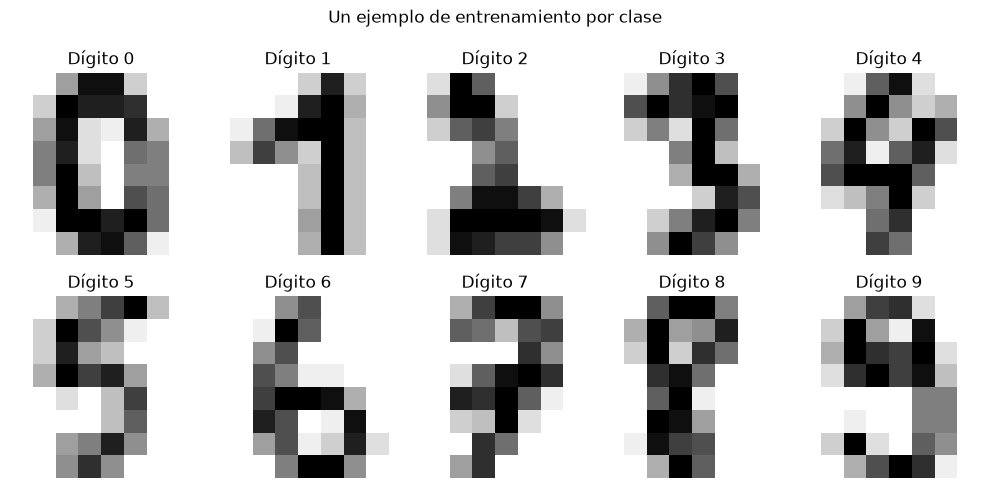

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5.2))
for digito, ax in zip(range(10), axes.ravel()):
    indice = np.flatnonzero(y_train == digito)[0]
    ax.imshow(X_train[indice].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Dígito {digito}")
    ax.axis("off")
fig.suptitle("Un ejemplo de entrenamiento por clase")
fig.tight_layout()
plt.show()


## 3. Las cuatro funciones de activación

La activación que cambiamos es la de la capa oculta. La salida, en un problema de varias clases, sigue siendo una softmax: convierte los 10 números finales en probabilidades que suman 1. Eso no lo tocamos.

identity. Devuelve el mismo número que recibe. No agrega curvatura. Aunque haya 30 neuronas, juntar capas lineales sigue siendo una transformación lineal, y como hay menos neuronas que píxeles la imagen se comprime de 64 a 30 antes de llegar a las clases. Las fronteras entre dígitos quedan rectas. Suele optimizarse rápido, pero se le dificulta separar números que se parecen.

logistic. Es la sigmoide. Aprieta cualquier entrada entre 0 y 1, y con eso la red ya puede doblar la frontera. El problema es la saturación: si la entrada es muy grande o muy chica, la salida se pega a 1 o a 0 y la derivada casi desaparece. El optimizador avanza más lento.

tanh. También tiene forma de S, pero la salida va de -1 a 1 y queda centrada en cero. Se satura en los extremos, igual que la sigmoide. Al pasar por cero suele entrenar un poco más cómoda que logistic, aunque tampoco es inmune a quedarse plana.

relu. Si el valor es negativo lo vuelve cero, y si es positivo lo deja igual. Del lado positivo no se satura, entonces el entrenamiento no se frena tanto, y varias neuronas quedan apagadas. Es la activación que normalmente se prueba primero en una red multicapa. En el cero tiene un quiebre, y para clasificar estos dígitos eso no estorba.


## 4. Qué medimos y cómo vamos a elegir

Para cada activación guardamos accuracy, balanced accuracy, precision macro, recall macro, F1 macro y kappa. También el log loss. Esa última no pregunta solo si el dígito ganador era el correcto: mira qué tan probable era la clase verdadera. Mientras más bajo, mejor.

En el ejemplo la regla era quedarse con la mayor balanced accuracy de validación. Si había empate, ganaba el menor log loss. La dejamos escrita así, antes de mirar la prueba. Aquí las clases están parejas, entonces accuracy y balanced accuracy van a salir muy cerca, pero no cambiamos el criterio a mitad de camino. Si todavía hubiera empate, ganaría la que use menos iteraciones.

El taller pide tener en cuenta el tiempo. Lo medimos, pero con una red de este tamaño el reloj da fracciones de segundo y, entre las que terminan igual de rápido, el orden puede cambiar si se vuelve a correr la celda. Las iteraciones no se mueven con la semilla fija, y esas sí dicen quién trabajó más. Un modelo que siempre responde el dígito más frecuente nos sirve de piso: si la red no le gana a eso, no está haciendo nada.


In [3]:
def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    clases = np.asarray(modelo.classes_)
    probabilidades = modelo.predict_proba(entradas)
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Balanced accuracy": balanced_accuracy_score(etiquetas, pred),
        "Precision macro": precision_score(etiquetas, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(etiquetas, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(etiquetas, pred, average="macro", zero_division=0),
        "Kappa": cohen_kappa_score(etiquetas, pred),
        "Log loss": log_loss(etiquetas, probabilidades, labels=clases),
    }


def construir_mlp(activacion):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(30,),
            activation=activacion,
            solver="lbfgs",
            alpha=1e-4,
            tol=1e-6,
            max_iter=2000,
            max_fun=50000,
            random_state=SEMILLA,
        )),
    ])


referencia = DummyClassifier(strategy="most_frequent", random_state=SEMILLA)
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_val)
print("Piso: siempre predecir el dígito más frecuente del entrenamiento.")
print("Accuracy en validación:", round(accuracy_score(y_val, pred_ref), 4))
print("Balanced accuracy en validación:", round(balanced_accuracy_score(y_val, pred_ref), 4))


Piso: siempre predecir el dígito más frecuente del entrenamiento.
Accuracy en validación: 0.1028
Balanced accuracy en validación: 0.1


## 5. Entrenamiento de las cuatro activaciones

Solo cambia la activación. El resto de la red, la semilla y las particiones quedan iguales. Si sale un aviso de convergencia lo dejamos anotado, porque significaría que el optimizador se topó con el tope de iteraciones.


identity: 24 iteraciones, 0.0824 s, avisos 0


logistic: 60 iteraciones, 0.1751 s, avisos 0


tanh: 22 iteraciones, 0.0747 s, avisos 0
relu: 24 iteraciones, 0.0547 s, avisos 0

Métricas de validación, salvo las dos columnas de entrenamiento:


,Accuracy train,Balanced train,Accuracy,Balanced accuracy,Precision macro,Recall macro,F1 macro,Kappa,Log loss,Iteraciones,Aviso convergencia,Segundos
Activación,,,,,,,,,,,,
identity,1.0,1.0,0.9444,0.9443,0.9452,0.9443,0.9444,0.9383,0.4962,24,False,0.0824
logistic,1.0,1.0,0.9639,0.9637,0.9654,0.9637,0.9639,0.9599,0.1193,60,False,0.1751
tanh,1.0,1.0,0.9583,0.9582,0.9599,0.9582,0.9584,0.9537,0.1868,22,False,0.0747
relu,1.0,1.0,0.9667,0.9667,0.9674,0.9667,0.9668,0.9630,0.2715,24,False,0.0547


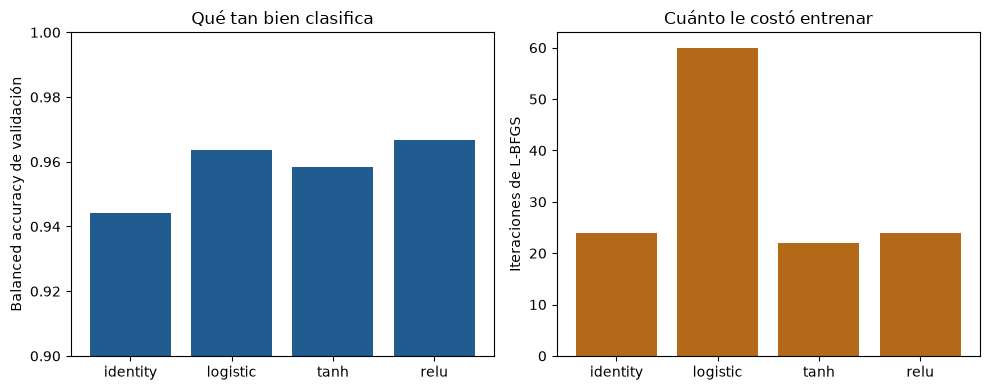

In [4]:
modelos = {}
filas = []
avisos_por_modelo = {}

for activacion in ["identity", "logistic", "tanh", "relu"]:
    modelo = construir_mlp(activacion)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]
    entrenamiento = evaluar(modelo, X_train, y_train)
    validacion = evaluar(modelo, X_val, y_val)
    filas.append({
        "Activación": activacion,
        "Accuracy train": entrenamiento["Accuracy"],
        "Balanced train": entrenamiento["Balanced accuracy"],
        **validacion,
        "Iteraciones": int(modelo.named_steps["mlp"].n_iter_),
        "Aviso convergencia": bool(mensajes),
        "Segundos": segundos,
    })
    modelos[activacion] = modelo
    avisos_por_modelo[activacion] = mensajes
    print(
        f"{activacion}: {int(modelo.named_steps['mlp'].n_iter_)} iteraciones, "
        f"{segundos:.4f} s, avisos {len(mensajes)}"
    )

resultados = pd.DataFrame(filas).set_index("Activación")
print("\nMétricas de validación, salvo las dos columnas de entrenamiento:")
display(resultados.round(4))

for activacion, mensajes in avisos_por_modelo.items():
    for mensaje in mensajes:
        print(f"Aviso de {activacion}: {mensaje.splitlines()[0]}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
orden = ["identity", "logistic", "tanh", "relu"]
axes[0].bar(orden, resultados.loc[orden, "Balanced accuracy"], color="#205C90")
axes[0].set_ylim(0.90, 1.0)
axes[0].set_ylabel("Balanced accuracy de validación")
axes[0].set_title("Qué tan bien clasifica")
axes[1].bar(orden, resultados.loc[orden, "Iteraciones"], color="#B46918")
axes[1].set_ylabel("Iteraciones de L-BFGS")
axes[1].set_title("Cuánto le costó entrenar")
fig.tight_layout()
plt.show()


## 6. Lectura de los resultados

Las cuatro convergieron sin aviso y las cuatro dejaron el entrenamiento en accuracy 1. Con alpha chiquito y L-BFGS, la red se aprende los dígitos con los que entrena. Eso no nos sirve para elegir. La diferencia está en validación, y las cuatro le ganan por mucho al piso de adivinar el dígito más común.

identity se queda en una balanced accuracy de 0.9443 y en el peor log loss, 0.4962, con 24 iteraciones. Era lo que se esperaba de una frontera recta: se le escapan dígitos que en 8 por 8 se parecen.

tanh sube a 0.9582, con el menor número de iteraciones de las cuatro: 22. logistic llega a 0.9637 y, además, tiene el mejor log loss (0.1193). Cuando acierta suele estar más segura, y cuando falla no se va tan al extremo. El costo es claro: usa 60 iteraciones, más del doble que las otras, y en el reloj se nota.

relu queda primera en balanced accuracy (0.9667) y también en F1, con 24 iteraciones. Está en el mismo grupo rápido que identity y tanh. La ventaja sobre logistic es pequeña: cabe más o menos en un dígito de los 360 de validación, así que no es una diferencia grande. Aun así es la que gana la regla que dejamos escrita. Si las tomáramos como empate, el desempate por iteraciones también se queda con relu, porque 24 es bastante menos que 60.

logistic sería la candidata si lo que nos importara fuera la calidad de las probabilidades y no la etiqueta. Para este taller, que es clasificar dígitos y cuidar el tiempo de entrenamiento, relu es la que conviene. identity no alcanza, y tanh clasifica peor que relu sin ahorrar un tiempo que de verdad se note.


## 7. Elección

Aplicamos la regla sobre la tabla de validación. La prueba sigue cerrada.


In [5]:
ranking = resultados.reset_index().sort_values(
    ["Balanced accuracy", "Log loss", "Iteraciones", "Activación"],
    ascending=[False, True, True, True],
    kind="mergesort",
)
mejor_activacion = ranking.iloc[0]["Activación"]
mejor_modelo = modelos[mejor_activacion]

print("Activación elegida:", mejor_activacion)
print("Balanced accuracy de validación:", round(ranking.iloc[0]["Balanced accuracy"], 4))
print("Log loss de validación:", round(ranking.iloc[0]["Log loss"], 4))
print("Iteraciones:", int(ranking.iloc[0]["Iteraciones"]))
print("Segundos de esta corrida:", round(ranking.iloc[0]["Segundos"], 4))
if avisos_por_modelo[mejor_activacion]:
    print("El modelo elegido tuvo aviso de convergencia.")
else:
    print("El modelo elegido convergió sin aviso.")

assert mejor_activacion == "relu"
assert int(resultados.loc["logistic", "Iteraciones"]) > int(resultados.loc["relu", "Iteraciones"])
assert resultados["Log loss"].idxmin() == "logistic"
assert resultados["Balanced accuracy"].idxmax() == "relu"
assert not resultados["Aviso convergencia"].any()
assert np.allclose(resultados["Accuracy train"], 1.0)


Activación elegida: relu
Balanced accuracy de validación: 0.9667
Log loss de validación: 0.2715
Iteraciones: 24
Segundos de esta corrida: 0.0547
El modelo elegido convergió sin aviso.


## 8. Prueba del modelo elegido

Ahora sí abrimos el 20 por ciento que estaba guardado. Solo evaluamos la activación que ya ganó. No usamos estos números para cambiar de opinión, porque eso sería elegir con la respuesta a la vista.


,Accuracy,Balanced accuracy,Precision macro,Recall macro,F1 macro,Kappa,Log loss
"Referencia, dígito más frecuente",0.1000,0.1000,0.0100,0.1000,0.0182,0.0000,32.4393
MLP con relu,0.9639,0.9636,0.9646,0.9636,0.9639,0.9599,0.1962


              precision    recall  f1-score   support

           0     0.9722    0.9722    0.9722        36
           1     0.8718    0.9444    0.9067        36
           2     0.9714    0.9714    0.9714        35
           3     1.0000    0.9730    0.9863        37
           4     1.0000    0.9722    0.9859        36
           5     0.9737    1.0000    0.9867        37
           6     0.9714    0.9444    0.9577        36
           7     1.0000    1.0000    1.0000        36
           8     0.9412    0.9143    0.9275        35
           9     0.9444    0.9444    0.9444        36

    accuracy                         0.9639       360
   macro avg     0.9646    0.9636    0.9639       360
weighted avg     0.9648    0.9639    0.9641       360



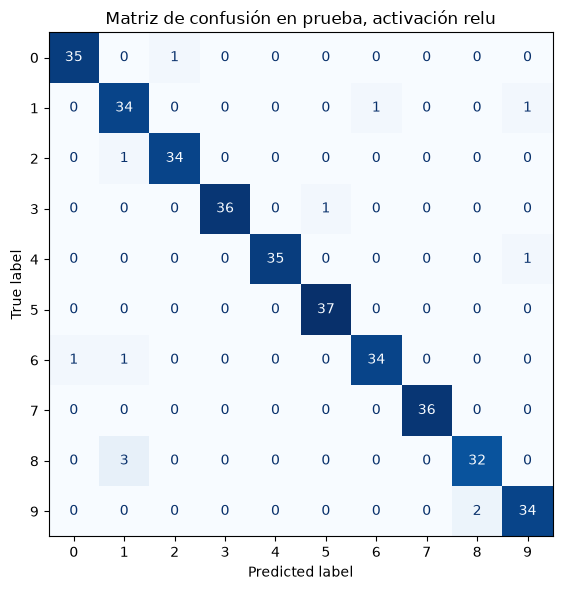

Confusiones en prueba, de la más repetida a la menos:
  real 8 predicho 1: 3
  real 9 predicho 8: 2
  real 6 predicho 1: 1
  real 6 predicho 0: 1
  real 4 predicho 9: 1
  real 3 predicho 5: 1
  real 2 predicho 1: 1
  real 1 predicho 9: 1
  real 1 predicho 6: 1
  real 0 predicho 2: 1
Total de errores: 13 de 360


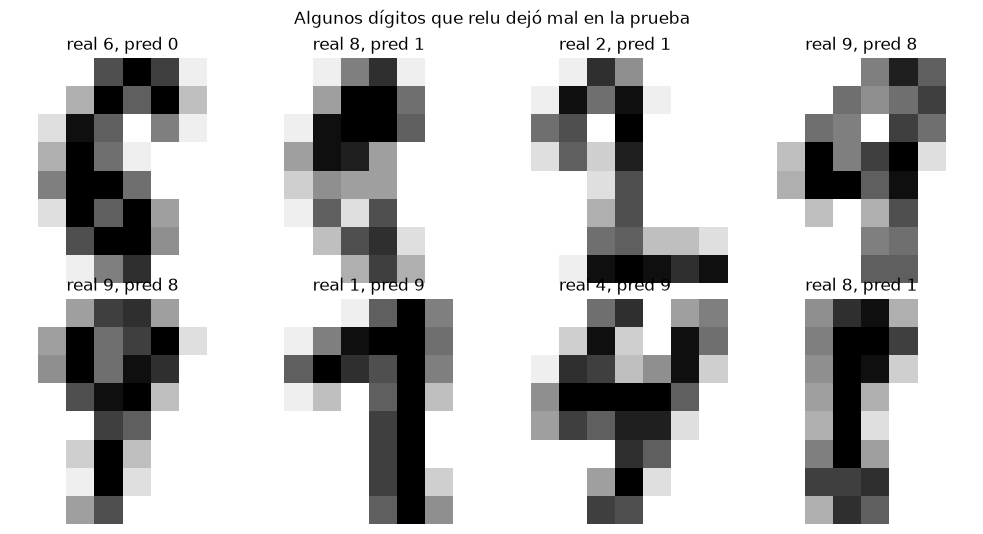

In [6]:
comparacion = pd.DataFrame({
    "Referencia, dígito más frecuente": evaluar(referencia, X_test, y_test),
    "MLP con relu": evaluar(mejor_modelo, X_test, y_test),
}).T
display(comparacion.round(4))

y_pred = mejor_modelo.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=np.arange(10),
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión en prueba, activación relu")
fig.tight_layout()
plt.show()

matriz = confusion_matrix(y_test, y_pred)
pares = []
for real in range(10):
    for predicho in range(10):
        if real != predicho and matriz[real, predicho] > 0:
            pares.append((int(matriz[real, predicho]), real, predicho))
pares.sort(reverse=True)
print("Confusiones en prueba, de la más repetida a la menos:")
for cantidad, real, predicho in pares:
    print(f"  real {real} predicho {predicho}: {cantidad}")

errores = np.flatnonzero(y_pred != y_test)
print(f"Total de errores: {len(errores)} de {len(y_test)}")

n_mostrar = min(8, len(errores))
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for ax, i in zip(axes.ravel(), errores[:n_mostrar]):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"real {y_test[i]}, pred {y_pred[i]}")
    ax.axis("off")
for ax in axes.ravel()[n_mostrar:]:
    ax.axis("off")
fig.suptitle("Algunos dígitos que relu dejó mal en la prueba")
fig.tight_layout()
plt.show()

assert mejor_activacion == "relu"
assert len(y_test) == 360
assert accuracy_score(y_test, y_pred) > accuracy_score(y_test, referencia.predict(X_test))


## 9. Cierre

Nos quedamos con relu.

En validación fue la que mejor clasificó, con 24 iteraciones, sin aviso de convergencia y sin pagar el costo de logistic, que necesitó 60. La diferencia de aciertos contra logistic es chica, y logistic estima mejor las probabilidades, pero el taller es de clasificar dígitos y pide mirar el tiempo. Con esa regla, relu conviene más.

identity se queda atrás porque el problema no es lineal: comprimir los 64 píxeles con una capa recta no alcanza para los dígitos que se parecen. tanh queda en el medio. En la prueba, relu se mantiene en el mismo rango que en validación, por encima de 0.96, así que no elegimos un modelo que solo se veía bien en el conjunto de selección.

Los errores que quedan son los de este dataset: un 8 que la red lee como 1, un 9 que lee como 8, y algunos sueltos. Con imágenes de 8 por 8 eso pasa, incluso mirándolas uno mismo.


## Referencias

El montaje sale del cuaderno de Eduardo Zurek, Perceptrón multicapa con datos sintéticos, en el repositorio de la clase.

La documentación que usamos para no inventar parámetros es la de MLPClassifier y la de redes neuronales supervisadas de scikit-learn:

https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

https://scikit-learn.org/stable/modules/neural_networks_supervised.html

La semilla fija hace que accuracy, log loss e iteraciones se repitan. El tiempo en segundos puede variar unas milésimas de una corrida a otra, sobre todo entre identity, tanh y relu, que terminan casi juntas. Las versiones de las librerías quedan impresas al inicio.
